# Tutorial 07: Your own isotherm
This notebook will guide you through adding a sorbent (and the model which describes it) of your own to pyDAC, without editing pyDAC.\
You will learn how to:
- write an isotherm model as an *equilibrium system*;
- test it on its own, before any simulation;
- register it, so that a case can name it;
- describe the sorbent in a *sorbent file*, and put it on top of a case;
- run the first steps of the built-in cycle with the new sorbent, from humid and from dry air.

A case chooses its isotherms by name, from the models pyDAC knows.\
Here we add a new one:
- **the sorbent**: APDES-NFC, an amine-functionalized nanofibrillated cellulose;
- **the model**: CO2/H2O co-adsorption, with the parameters published by\
  Stampi-Bombelli, van der Spek and Mazzotti, *Adsorption* 26 (2020) 1183–1197,
  [doi:10.1007/s10450-020-00249-w](https://doi.org/10.1007/s10450-020-00249-w).

### Overview
- **Case:** [`../cases/07_new_isotherm.json`](../cases/07_new_isotherm.json):
  the built-in cycle up to steam desorption (startup, blowdown, heating, desorption) on a 1D grid of 25 cells,
  every step stopped on time (an arbitrary choice: both runs get the same step durations).
- **Sorbent file:** [`../cases/07_apdes_nfc_sorbent.json`](../cases/07_apdes_nfc_sorbent.json):
  the properties, isotherm and kinetics of APDES-NFC.
- **Runtime:** two step runs of about 40 seconds each; about 50 MB on disk.
- **Without a notebook:** none. A registered model exists only in Python, so this tutorial has no terminal version.
- **Guide:** [Extending pyDAC](../../docs/guide/08_extending.md).

### Before you start
1. Install pyDAC and select its kernel, as in [tutorial 01](01_first_steps.ipynb).
2. Run the cells in order, from the top: the model is registered in this Python session only.

The results are written under `simulation_results/`, next to this notebook.

In [1]:
# Import necessary libraries
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

import pydac
from pydac.core.isotherm_models import water_saturation_pressure

# The case file, the sorbent file, and the gas constant
CASE = Path("../cases/07_new_isotherm.json")
SORBENT_FILE = Path("../cases/07_apdes_nfc_sorbent.json")
R = 8.314462618  # J/(mol K)

## The model

On APDES-NFC:
- the water loading does not depend on the CO2;
- the CO2 loading grows with the adsorbed water.

**Water**: a GAB isotherm in the relative humidity $x = p_\mathrm{H_2O}/p_\mathrm{sat}(T)$ (Eq. 6 of [Stampi-Bombelli et al.](https://doi.org/10.1007/s10450-020-00249-w)):

$$q_\mathrm{H_2O} = c_m\,\frac{c_G K_\mathrm{ads}\,x}{(1 - K_\mathrm{ads}x)\,(1 + (c_G - 1)K_\mathrm{ads}x)}$$

**CO2**: a Toth isotherm whose capacity $n_s$ and affinity $b$ grow with the adsorbed water,\
the "modified Toth" (their Eqs. 8–14):

$$q_\mathrm{CO_2} = \frac{n_s\,b\,p_\mathrm{CO_2}}{\left[1 + (b\,p_\mathrm{CO_2})^{t}\right]^{1/t}}, \qquad
n_s = \frac{n_{s0}\,e^{\chi(1 - T/T_0)}}{1 - \gamma\,q_\mathrm{H_2O}}, \qquad
b = b_0\,e^{\frac{\Delta H_0}{R T_0}\left(\frac{T_0}{T} - 1\right)}\,(1 + \beta\,q_\mathrm{H_2O}), \qquad
t = t_0 + \alpha\left(1 - \frac{T_0}{T}\right)$$

The parameters are those of their Table 2, with two remarks:

**1. $b_0$**
- Table 2 gives $b_0 = 70.74 \times 10^4\ \mathrm{kPa^{-1}}$.
- With that value the dry isotherm is nearly flat (about 2.3–2.4 mol/kg from 1 to 100 kPa at 296 K, 1.9–2.2 at 343 K),\
  and misses their measurements (Fig. 1b).
- With $b_0 = 70.74\ \mathrm{kPa^{-1}}$ it follows them.
- This notebook uses that value: $0.07074\ \mathrm{Pa^{-1}}$.

**2. $b(T)$** is used as printed.
- With the negative $\Delta H_0$, the affinity grows with temperature.
- The loading still falls with temperature, through $t(T)$ ($\alpha < 0$), as in the measurements.
- The model holds only while $t > 0$: below 399 K.

The relative humidity uses pyDAC's water vapor pressure (IAPWS-1995):\
the one the simulation uses for the feed humidity and the steam.

The parameters are in the sorbent file, with the rest of the sorbent:

In [2]:
# Read the sorbent file and show the parameters of the new model
SORBENT = json.loads(SORBENT_FILE.read_text())
PARAMETERS = SORBENT["adsorption"]["equilibrium_systems"]["ModifiedTothGAB"]["parameters"]
PARAMETERS

{'T0_K': 296.0,
 'ns0_mol_per_kg': 2.38,
 'b0_inverse_Pa': 0.07074,
 't0': 0.4148,
 'dH0_J_per_mol': -57047.0,
 'alpha': -1.606,
 'chi': 0.0,
 'gamma_kg_per_mol': 0.0061,
 'beta_kg_per_mol': 28.907,
 'cG': 0.1489,
 'K_ads': 0.5751,
 'cm_mol_per_kg': 36.48}

## The `EquilibriumSystem` of pyDAC

How pyDAC calls an equilibrium system:
- **inputs**: the partial pressures (Pa) and the loadings (mol/kg) by species name, and the temperature (K);
- all as NumPy arrays, with one value per cell;
- **output**: the equilibrium loading of each species it owns.

This system owns CO2 and H2O, because the CO2 isotherm model needs the water loading:

In [3]:
class ModifiedTothGAB(pydac.EquilibriumSystem):
    # GAB for H2O and the water-dependent Toth for CO2 (Stampi-Bombelli et al. 2020).

    # The species this system owns
    species = ("CO2", "H2O")

    def __init__(self, *, T0_K, ns0_mol_per_kg, b0_inverse_Pa, t0, dH0_J_per_mol, alpha, chi,
                 gamma_kg_per_mol, beta_kg_per_mol, cG, K_ads, cm_mol_per_kg):
        # Store the parameters of Table 2 of Stampi-Bombelli et al. (2020)
        self.T0, self.ns0, self.b0, self.t0 = T0_K, ns0_mol_per_kg, b0_inverse_Pa, t0
        self.dH0, self.alpha, self.chi = dH0_J_per_mol, alpha, chi
        self.gamma, self.beta = gamma_kg_per_mol, beta_kg_per_mol
        self.cG, self.K, self.cm = cG, K_ads, cm_mol_per_kg

    def h2o(self, p_H2O, T):
        # GAB isotherm. Above saturation the loading stays at its value at x = 1.
        x = np.clip(p_H2O / water_saturation_pressure(T), 0.0, 1.0)
        Kx = self.K * x
        return self.cm * self.cG * Kx / ((1.0 - Kx) * (1.0 + (self.cG - 1.0) * Kx))

    def co2(self, p_CO2, T, q_H2O):
        # Modified Toth: refuse temperatures or water loadings outside the model's range
        t = self.t0 + self.alpha * (1.0 - self.T0 / T)
        if np.any(t <= 0.0) or np.any(self.gamma * q_H2O >= 1.0):
            raise ValueError("ModifiedTothGAB is used outside its range (T >= 399 K or "
                             "too much adsorbed water).")
        ns = self.ns0 * np.exp(self.chi * (1.0 - T / self.T0)) / (1.0 - self.gamma * q_H2O)
        b = (self.b0 * np.exp(self.dH0 / (R * self.T0) * (self.T0 / T - 1.0))
             * (1.0 + self.beta * q_H2O))
        return ns * b * p_CO2 / (1.0 + (b * p_CO2) ** t) ** (1.0 / t)

    def equilibrium_loadings(self, *, partial_pressures_Pa, temperature_K,
                             current_loadings_mol_per_kg):
        # What pyDAC calls: CO2 reads the CURRENT water loading, H2O only its own pressure
        T = temperature_K
        return {"CO2": self.co2(partial_pressures_Pa["CO2"], T, current_loadings_mol_per_kg["H2O"]),
                "H2O": self.h2o(partial_pressures_Pa["H2O"], T)}

Note: the CO2 equilibrium uses the **current** water loading of the solid, not the equilibrium one.\
So when the bed dries, its CO2 affinity falls with it.

Before going to a simulation, test it on its own!
- **left**: the dry isotherms of Fig. 1b of [Stampi-Bombelli et al.](https://doi.org/10.1007/s10450-020-00249-w), and the humid one at 296 K ($p_\mathrm{H_2O}$ = 2.55 kPa);
- **right**: air at 25 °C with 400 ppm CO2, at increasing humidity, with the solid at equilibrium with both.

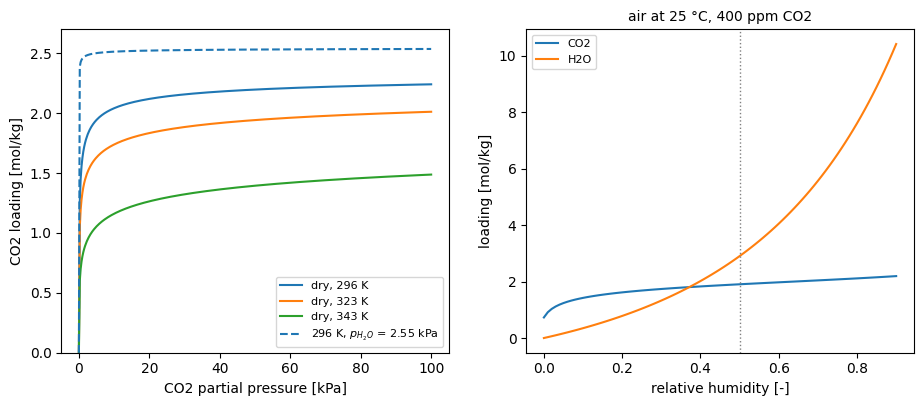

air at 25 °C, 400 ppm CO2: dry 0.729 mol/kg CO2; at RH 0.5 1.904 mol/kg CO2 with 2.90 mol/kg H2O


In [4]:
# Build the model from the parameters of the sorbent file
model = ModifiedTothGAB(**PARAMETERS)

# Air at 25 °C, 400 ppm CO2, relative humidity from 0 to 0.9: loadings at equilibrium
p = np.linspace(0.0, 1.0e5, 400)
rh = np.linspace(0.0, 0.9, 91)
T_air, p_CO2_air = 298.15, 400e-6 * 101325.0
q_H2O_air = model.h2o(rh * water_saturation_pressure(T_air), T_air)
q_CO2_air = model.co2(p_CO2_air, T_air, q_H2O_air)

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.2))

# Left: dry CO2 isotherms at three temperatures, and the humid one at 296 K (dashed)
for T in [296.0, 323.0, 343.0]:
    left.plot(p / 1e3, model.co2(p, T, 0.0), label=f"dry, {T:.0f} K")
humid = model.h2o(2550.0, 296.0)
left.plot(p / 1e3, model.co2(p, 296.0, humid), "--", color="C0", label="296 K, $p_{H_2O}$ = 2.55 kPa")
left.set_xlabel("CO2 partial pressure [kPa]")
left.set_ylabel("CO2 loading [mol/kg]")
left.set_ylim(0, 2.7)
left.legend(fontsize=8)

# Right: CO2 and H2O loadings from air against the relative humidity (dotted line: RH 0.5)
right.plot(rh, q_CO2_air, label="CO2")
right.plot(rh, q_H2O_air, label="H2O")
right.axvline(0.5, color="gray", linestyle=":", linewidth=1)
right.set_xlabel("relative humidity [-]")
right.set_ylabel("loading [mol/kg]")
right.set_title("air at 25 °C, 400 ppm CO2", fontsize=10)
right.legend(fontsize=8)
plt.show()

# The two numbers we compare with the simulation later: dry air and RH 0.5
at_feed = np.isclose(rh, 0.5)
print(f"air at 25 °C, 400 ppm CO2: dry {q_CO2_air[0]:.3f} mol/kg CO2; at RH 0.5 "
      f"{q_CO2_air[at_feed][0]:.3f} mol/kg CO2 with {q_H2O_air[at_feed][0]:.2f} mol/kg H2O")

The water raises the CO2 capacity of APDES-NFC from humid air by a factor of about 2.6.

## Register the new equilibrium system
If a *new* equilibrium system is created, it must be registered first. Until it is registered, a case that uses it is refused when it is loaded:

In [5]:
# Load the case with the sorbent file on top, before registering: we expect a refusal
try:
    pydac.load_case(CASE, settings=SORBENT)
except pydac.ConfigurationError as error:
    print(error)

Invalid resolved experiment configuration: Unknown model 'ModifiedTothGAB'. Available models: Toth, GAB, TothGABWADST, CompetitiveSips.


To register the model, give pyDAC a **registry entry**: a short description of the system, field by field.\
pyDAC reads it when a case is loaded, and refuses a case that does not fit, before any simulation:
- `adsorbates=("CO2", "H2O")`: the species whose loading this system gives (its `species`).
  - Together, the systems of a case must give every adsorbate exactly once.
- `required_gas_species=("CO2", "H2O")`: the gases that must be in the mixture of the case,
  because the isotherms read their partial pressures.
  - A case that uses this new isotherm is refused if CO2 or H2O is not in its mixture.
- `required_current_loadings=("H2O",)`: the loadings the system reads from the solid as it is *now*\
  (`current_loadings_mol_per_kg`, not the equilibrium ones).
  - Here the CO2 isotherm needs the water already adsorbed, so H2O must be an adsorbate of the case.
- `build`: how pyDAC makes the system from the case.
  - It passes the parameters of the sorbent file to `ModifiedTothGAB(...)`.
  - `datasets` are tables some models read; this one reads none.
- `required_parameters`: this entry indicates the parameters that the sorbent file must give; here every name of `PARAMETERS`.
  - A missing name, or one that is not in the list, is refused.

In [6]:
# Register the model under the name the sorbent file uses
pydac.register_equilibrium("ModifiedTothGAB", pydac.EquilibriumRegistryEntry(
    adsorbates=("CO2", "H2O"),
    required_gas_species=("CO2", "H2O"),
    required_current_loadings=("H2O",),
    build=lambda datasets, parameters: ModifiedTothGAB(**parameters),
    required_parameters=tuple(PARAMETERS),
))

## The json sorbent file

The file holds the **two blocks** of a case that together *describe* a sorbent:
- `sorbent`: its properties;
- `adsorption`: its equilibrium system and kinetic laws.

Let's take a look at it:

In [7]:
# Show the sorbent properties and the kinetics of the sorbent file
print(json.dumps(SORBENT["sorbent"], indent=2))
print(json.dumps(SORBENT["adsorption"]["kinetics"], indent=2))

{
  "density_kg_m3": 61.0,
  "porosity": 0.9616,
  "particle_radius_m": 0.00375,
  "heat_capacity": {
    "model": "constant",
    "parameters": {
      "value_J_kgK": 2070.0
    }
  },
  "heats_of_adsorption_J_mol": {
    "CO2": -57000.0,
    "H2O": -49000.0
  }
}
{
  "CO2": {
    "model": "LDF",
    "parameters": {
      "k_LDF_s_inv": 0.0002
    }
  },
  "H2O": {
    "model": "LDF",
    "parameters": {
      "k_LDF_s_inv": 0.002
    }
  }
}


From Table 1 of [Stampi-Bombelli et al.](https://doi.org/10.1007/s10450-020-00249-w):
- the particle density (61 kg/m³) and diameter (7.5 mm);
- the particle porosity, from the particle and material densities ($1 - 61/1590 = 0.9616$);
- the solid heat capacity (2070 J/(kg K));
- the heats of adsorption (−57 kJ/mol CO2, −49 kJ/mol H2O);
- the linear-driving-force coefficients ($2\times10^{-4}$ 1/s CO2, $2\times10^{-3}$ 1/s H2O).

The conductivity and the pore radius are left out, we keep pyDAC's default values.

The bed void fraction belongs to the case, not to the sorbent:
- here it is the default, 0.38;
- so the bed holds less sorbent per volume than their bed (55.4 kg/m³).

Now finally, we place the file on top of the case:
- the `sorbent` fields will replace the default ones;
- the `equilibrium_systems` and `kinetics` mappings are replaced as a whole.

In [8]:
# The case with the sorbent file on top: now accepted
case = pydac.load_case(CASE, settings=SORBENT)

# How much sorbent the bed holds
bed_volume = case.simulation.geometry.volume_m3
eps_b = case.simulation.bed.design["eps_b"]
sorbent_kg = (1.0 - eps_b) * case.simulation.sorbent.density_kg_m3 * bed_volume
print(f"bed {1000 * bed_volume:.1f} L, eps_b {eps_b}, sorbent {1000 * sorbent_kg:.1f} g")

bed 1.0 L, eps_b 0.38, sorbent 37.8 g


## Run it

Two runs of the same steps, on APDES-NFC:
1. **humid air**: the case as it is; the startup feeds air at 25 °C, with 400 ppm CO2 and 50 % relative humidity;
2. **dry air**: the same, with `relative_humidity` 0 in the startup, to see what the water does.

In [9]:
# The two cases: as it is, and with dry air in the startup
cases = {
    "humid air": case,
    "dry air": pydac.load_case(CASE, settings=SORBENT | {
        "steps.startup.composition.relative_humidity": 0.0}),
}

# Run both and print their run folders
results = {name: pydac.run_steps(case, overwrite=True) for name, case in cases.items()}
for name, result in results.items():
    print(f"{name:10s} {result.folder.name}")

Overwrite: deleted /path/to/pyDAC/examples/notebooks/simulation_results/step_mode/tutorial_07_packed_bed_ef3e12ee
Run folder: /path/to/pyDAC/examples/notebooks/simulation_results/step_mode/tutorial_07_packed_bed_ef3e12ee



------------------------------------------------------------
           Thermodynamic + Kinetic Models Setup             
------------------------------------------------------------
Results will be saved in: simulation_results/step_mode/tutorial_07_packed_bed_ef3e12ee

                                               Starting Adsorption Cycle                                                
[TVSA] Starting step 'Startup' with solve=True, termination=time.
[TVSA] Completed step 'Startup' with stop=final time @ 39000.00 s.
[TVSA] Starting step 'Blowdown' with solve=True, termination=time.
[TVSA] Completed step 'Blowdown' with stop=final time @ 180.00 s.
[TVSA] Starting step 'Wall pre-heating' with solve=True, termination=time.
[TVSA] Completed step 'Wall pre-heating' with stop=final time @ 9000.00 s.
[TVSA] Starting step 'Desorption (steam-assisted)' with solve=True, termination=time.
[TVSA] Completed step 'Desorption (steam-assisted)' with stop=final time @ 3600.00 s.

                  

Let's inspect `kpis.csv` via python code. We extract here the change of the CO2 and H2O inventories of the column\
(positive: the column took it up):

In [10]:
# The steps of this case, in the order they are run
STEPS = ["startup", "blow", "heat", "s_des"]


def changes(result, species):
    # Change of one species in the column, step by step, in grams
    values = {}
    for step in STEPS:
        table = pd.read_csv(result.results_folder / step / "kpis.csv")
        value = table.set_index(["Species", "KPI"])["Value"]
        values[step] = 1000 * value[species, "mass change [kg]"]
    return values


# One column per (feed, species)
table = pd.DataFrame({(name, species): changes(result, species)
                      for name, result in results.items() for species in ["CO2", "H2O"]})
table.columns.names = ["feed", "change [g]"]
table.round(3)

feed       humid air        dry air       
change [g]       CO2    H2O     CO2    H2O
startup        3.168  1.989   1.213  0.000
blow          -0.001 -0.010  -0.001 -0.000
heat          -2.119 -1.837  -0.639  0.000
s_des         -0.212  0.495  -0.266  0.637

In [11]:
# CO2 loading after the startup: grams -> mol per kg of sorbent
for name, result in results.items():
    loading = table[name, "CO2"]["startup"] / 1000 / 0.04401 / sorbent_kg
    print(f"{name:10s} CO2 loading after the startup {loading:.3f} mol/kg")

humid air  CO2 loading after the startup 1.903 mol/kg
dry air    CO2 loading after the startup 0.729 mol/kg


What the numbers tell us:
- **After the 39000 s startup** the bed is at equilibrium with the feed:
  - 1.903 mol/kg CO2 from humid air, and 0.729 mol/kg from dry air;
  - close to the values of the isotherm test above.
- **From humid air** the column takes up 3.17 g CO2 and 1.99 g H2O; **from dry air** 1.21 g CO2.

The steps after the startup are those of the built-in cycle, made for Lewatit.\
They do not suit APDES-NFC:
- it loses most of its CO2 in the 2.5 h of heating to 100 °C:
  - 2.12 of the 3.17 g after humid air;
  - 0.64 of the 1.21 g after dry air;
- the heating step does not collect a product, so that CO2 goes to the vent;
- the steam desorption then releases only 0.21 g and 0.27 g, and almost all of it dissolves in the condensed steam:\
  less than 1 mg reaches the product;
- during the heating the bed also dries (−1.84 g H2O), which lowers its CO2 affinity further.

A cycle for this sorbent needs other steps: a shorter heating, or a product collected earlier\
([tutorial 02](02_custom_case.ipynb) changes steps, [tutorial 05](05_nsga2_trial.ipynb) searches them).

Each run *saved* all its step profiles under `STEP/profiles/`, go and look at the particular ones you want.\
For example, the gas leaving the column during the heating, after humid air:

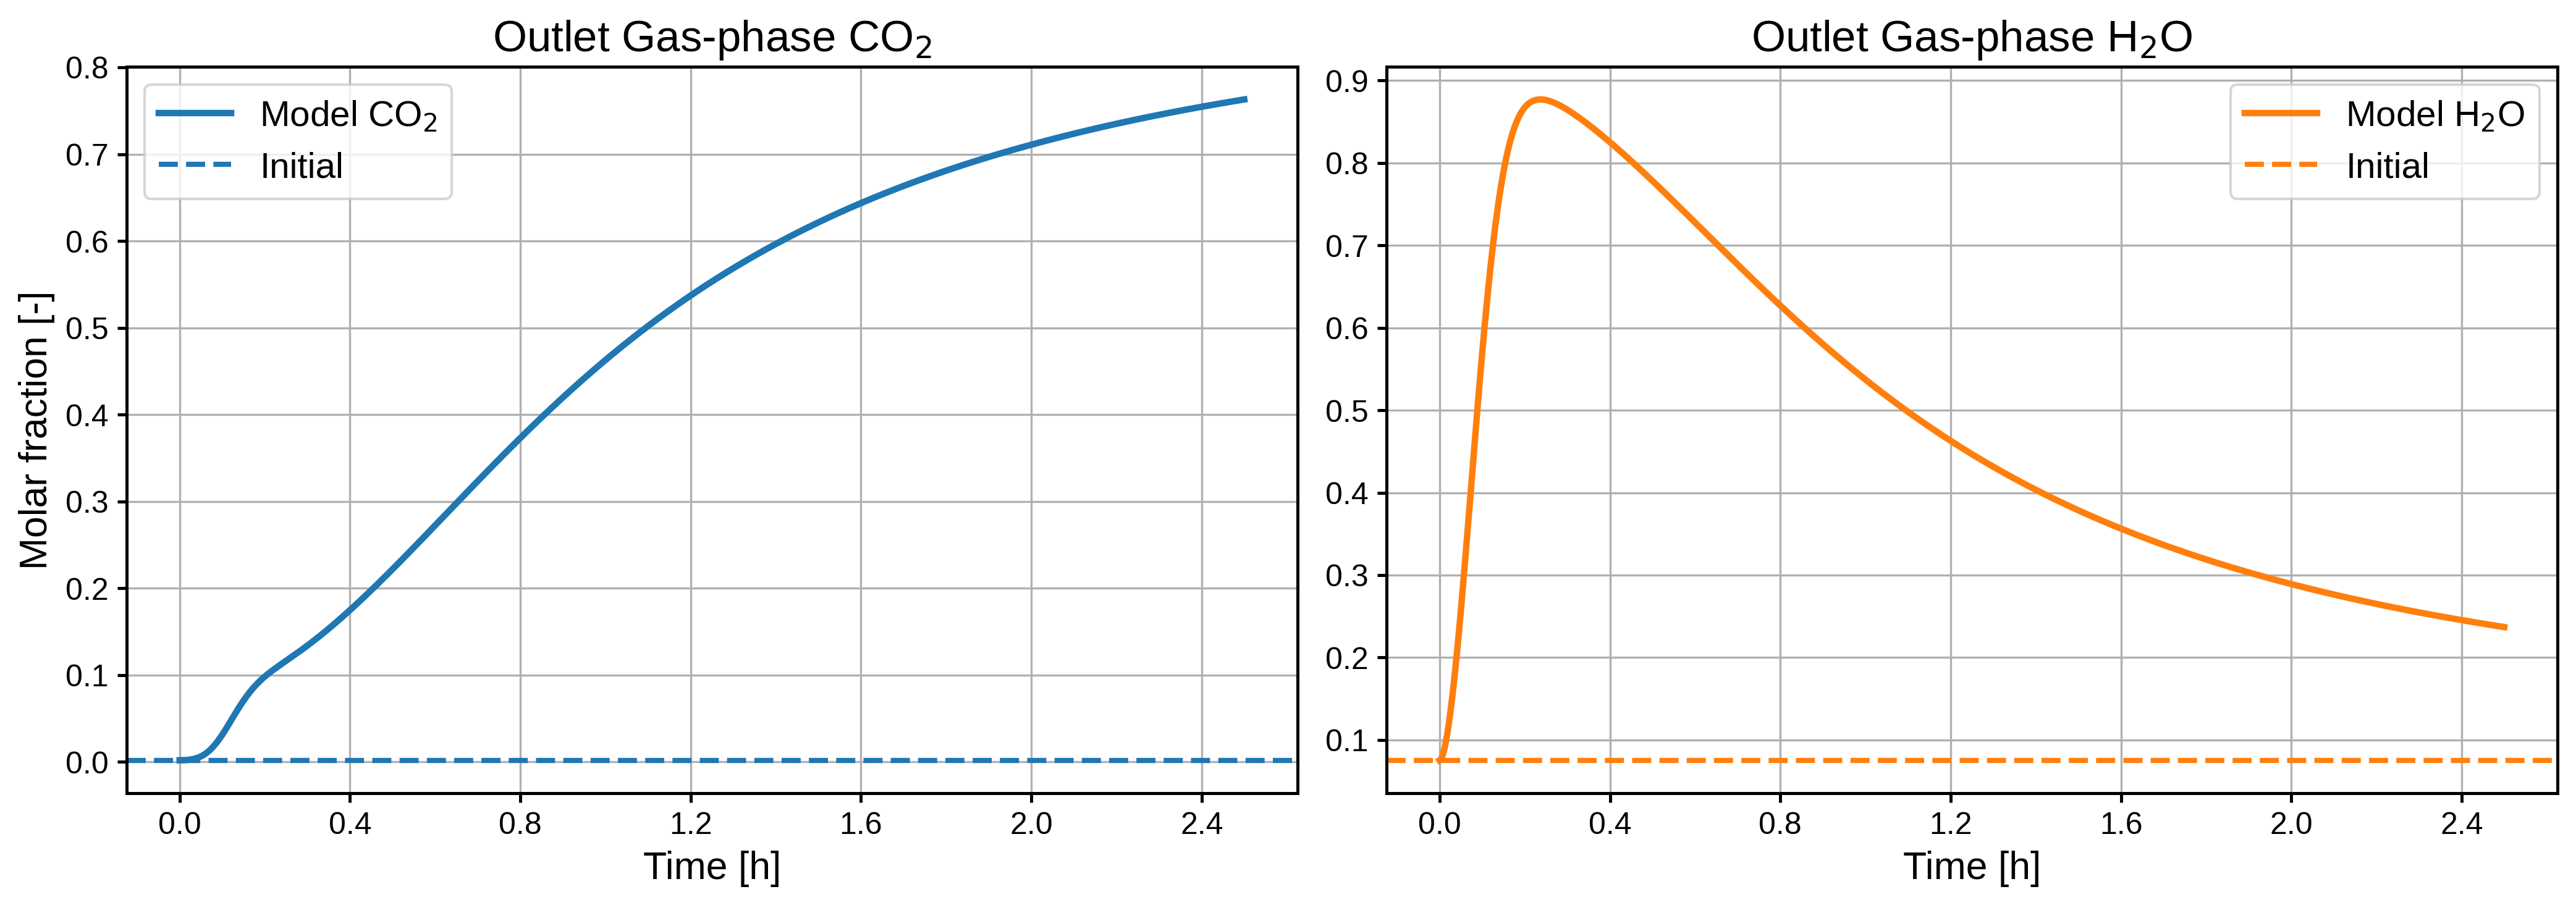

In [12]:
# Outlet composition during heat, humid-air run
display(Image(filename=results["humid air"].results_folder
              / "heat/profiles/outlet_profiles/heat_outlet_species.png", width=750))

## What the case records

The frozen case stores the **name** of the model and its **parameters**, not the Python code of `ModifiedTothGAB`.\
The fingerprint of the run folder is computed from the case, so it does not see the code either.

This is all the case knows about the model:

In [13]:
# The model's parameters, as the case stores them
print(dict(case.simulation.adsorption.equilibrium_systems["ModifiedTothGAB"].parameters))

{'T0_K': 296.0, 'ns0_mol_per_kg': 2.38, 'b0_inverse_Pa': 0.07074, 't0': 0.4148, 'dH0_J_per_mol': -57047.0, 'alpha': -1.606, 'chi': 0.0, 'gamma_kg_per_mol': 0.0061, 'beta_kg_per_mol': 28.907, 'cG': 0.1489, 'K_ads': 0.5751, 'cm_mol_per_kg': 36.48}


Good to know:
- **One Python session.** The registration lasts as long as this Python session.
  - In a new one, run the registration again before you load a case that names `ModifiedTothGAB`, \
  or resume one of its runs.
  - Reading saved results (`pydac.report`, `CycleDataLoader`) needs no registration;\
    redrawing the step plots with `pydac.report(..., snapshot_times=...)` does: it loads the case again.
- **Not from the terminal.** The `pydac` command knows only the built-in models.
- **The case does not see your code.** Say you change the equations of `ModifiedTothGAB`, but keep its name and parameters:
  - the case and its fingerprint stay the same, so the run goes to the same run folder as before;
  - a new run there is refused, and with `overwrite=True` it deletes the old results;
  - nothing in the run folder says which version of the code made them.
  - So give a changed model a new name (for example `ModifiedTothGAB_v2`), and keep its code next to your results.
- **NSGA-II campaigns** with several workers see the model only where the workers are forked from this session\
  (Linux, Python 3.13 or older). Elsewhere, use one worker.

Where to go next:
- The same sorbent file goes on top of any other case.
- Another sorbent file on top of this case compares sorbents\
  ([A sorbent of your own](../../docs/guide/08_extending.md#a-sorbent-of-your-own)).
- A kinetic law is registered the same way, with `pydac.register_kinetics`: see [Extending pyDAC](../../docs/guide/08_extending.md).
- To make your model part of pyDAC for every user, add it to the package ([CONTRIBUTING](../../CONTRIBUTING.md#extending-the-model)).

**Previous:** [Tutorial 06: Reproduce the breakthrough validation](06_breakthrough_validation.ipynb).